In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

font_manager.fontManager.addfont(r"C:\Windows\Fonts\malgun.ttf")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
train = pd.read_csv("./train.csv")
test = pd.read_csv("./test.csv")
submission = pd.read_csv("./sample_submission.csv")

print("train shape :", train.shape)
print("test shape :", test.shape)
print("submission shape :", submission.shape)

train.head()

train shape : (381109, 12)
test shape : (127037, 11)
submission shape : (127037, 2)


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [3]:
X = train.drop(columns=["id", "Response"]).copy()
y = train["Response"].copy()

X_test = test.drop(columns=["id"]).copy()

In [4]:
# Vehicle_Damage 변환
damage_map = {
    "NO": 0,
    "Yes": 1
}

X["Vehicle_Damage"] = X["Vehicle_Damage"].map(damage_map)
X_test["Vehicle_Damage"] = X_test["Vehicle_Damage"].map(damage_map)

# Gender 변환
gender_map = {
    "Female": 0,
    "Male": 1
}
X["Gender"] = X["Gender"].map(gender_map)
X_test["Gender"] = X_test["Gender"].map(gender_map)

In [5]:
# column 별 데이터 확인
print("Gender")
print(X["Gender"].value_counts())
print()
print("Age")
print(X["Age"].value_counts())
print()
print("Driving_License")
print(X["Driving_License"].value_counts())
print()
print("Region_Code")
print(X["Region_Code"].value_counts())
print("Previously_Insured")
print(X["Previously_Insured"].value_counts())
print()
print("Vehicle_Age")
print(X["Vehicle_Age"].value_counts())
print()
print("Vehicle_Damage")
print(X["Vehicle_Damage"].value_counts())
print()
print("Annual_Premium")
print(X["Annual_Premium"].value_counts())
print()
print("Policy_Sales_Channel")
print(X["Policy_Sales_Channel"].value_counts())
print()
print("Vintage")
print(X["Vintage"].value_counts())

Gender
1    206089
0    175020
Name: Gender, dtype: int64

Age
24    25960
23    24256
22    20964
25    20636
21    16457
      ...  
81       56
82       29
83       22
84       11
85       11
Name: Age, Length: 66, dtype: int64

Driving_License
1    380297
0       812
Name: Driving_License, dtype: int64

Region_Code
28.0    106415
8.0      33877
46.0     19749
41.0     18263
15.0     13308
30.0     12191
29.0     11065
50.0     10243
3.0       9251
11.0      9232
36.0      8797
33.0      7654
47.0      7436
35.0      6942
6.0       6280
45.0      5605
37.0      5501
18.0      5153
48.0      4681
14.0      4678
39.0      4644
10.0      4374
21.0      4266
2.0       4038
13.0      4036
7.0       3279
12.0      3198
9.0       3101
27.0      2823
32.0      2787
43.0      2639
17.0      2617
26.0      2587
25.0      2503
24.0      2415
38.0      2026
0.0       2021
16.0      2007
31.0      1960
23.0      1960
20.0      1935
49.0      1832
4.0       1801
34.0      1664
19.0      1535
22.0

In [6]:
# column 데이터 구분
categorical_cols = [
    "Region_Code",
    "Vehicle_Age",
    "Policy_Sales_Channel"
]

numeric_cols = [
    "Age",
    "Annual_Premium",
    "Vintage"
]

binary_cols = [
    "Gender",
    "Driving_License",
    "previously_Insured",
    "Vehicle_Damage"
]

print("범주형 :", categorical_cols)
print("수치형 :", numeric_cols)
print("이진형 :", binary_cols)

범주형 : ['Region_Code', 'Vehicle_Age', 'Policy_Sales_Channel']
수치형 : ['Age', 'Annual_Premium', 'Vintage']
이진형 : ['Gender', 'Driving_License', 'previously_Insured', 'Vehicle_Damage']


In [ ]:
# 결측치, 이상치, 데이터 타입 확인
print("데이터 크기:", train.shape)
print("\n자료형:")
print(train.dtypes)
print("\n결측치 수:")
display(train.isnull().sum().to_frame("missing_count"))
print("\n기초 통계:")
display(train.describe().T)
# IQR을 이용한 이상치 탐색

numeric_columns = X.select_dtypes(include=["number"]).columns

outlier_results = []

for column in numeric_columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = ((X[column] < lower) | (X[column] > upper)).sum()

    outlier_results.append({
        "변수": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "하한": lower,
        "상한": upper,
        "이상치 개수": outlier_count
    })

print("\n이상치 수:" )
outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.sort_values("이상치 개수", ascending=False))

데이터 크기: (381109, 12)

자료형:
id                        int64
Gender                   object
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age              object
Vehicle_Damage           object
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object

결측치 수:


,missing_count
id,0
Gender,0
Age,0
Driving_License,0
Region_Code,0
Previously_Insured,0
Vehicle_Age,0
Vehicle_Damage,0
Annual_Premium,0
Policy_Sales_Channel,0



기초 통계:


,count,mean,std,min,25%,50%,75%,max
id,381109.0,190555.000000,110016.836208,1.0,95278.0,190555.0,285832.0,381109.0
Age,381109.0,38.822584,15.511611,20.0,25.0,36.0,49.0,85.0
Driving_License,381109.0,0.997869,0.046110,0.0,1.0,1.0,1.0,1.0
Region_Code,381109.0,26.388807,13.229888,0.0,15.0,28.0,35.0,52.0
Previously_Insured,381109.0,0.458210,0.498251,0.0,0.0,0.0,1.0,1.0
Annual_Premium,381109.0,30564.389581,17213.155057,2630.0,24405.0,31669.0,39400.0,540165.0
Policy_Sales_Channel,381109.0,112.034295,54.203995,1.0,29.0,133.0,152.0,163.0
Vintage,381109.0,154.347397,83.671304,10.0,82.0,154.0,227.0,299.0
Response,381109.0,0.122563,0.327936,0.0,0.0,0.0,0.0,1.0



이상치 수:


,변수,Q1,Q3,IQR,하한,상한,이상치 개수
4,Annual_Premium,24405.0,39400.0,14995.0,1912.5,61892.5,10320
1,Driving_License,1.0,1.0,0.0,1.0,1.0,812
0,Age,25.0,49.0,24.0,-11.0,85.0,0
2,Region_Code,15.0,35.0,20.0,-15.0,65.0,0
3,Previously_Insured,0.0,1.0,1.0,-1.5,2.5,0
5,Policy_Sales_Channel,29.0,152.0,123.0,-155.5,336.5,0
6,Vintage,82.0,227.0,145.0,-135.5,444.5,0


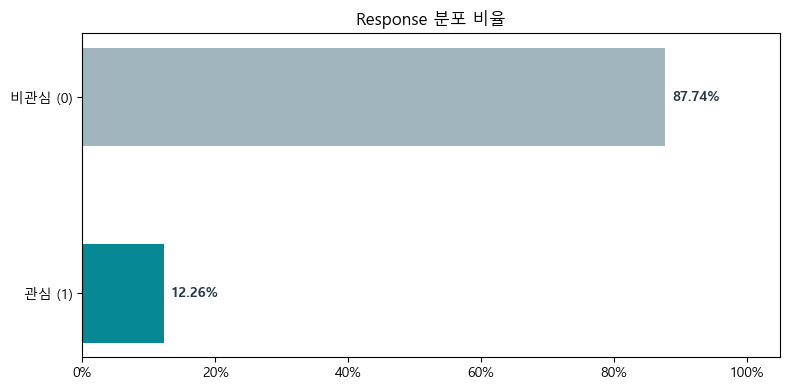

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 고객 비율 계산
response_ratio = train["Response"].value_counts(normalize=True).sort_index()

# 그래프에 표시할 이름과 비율
labels = ["비관심 (0)", "관심 (1)"]
percentages = response_ratio.values * 100

# 가로 막대그래프
plt.figure(figsize=(8, 4))
bars = plt.barh(labels, percentages,
                color=["#A0B5BD", "#078895"], height=0.5)

# 막대 끝에 비율 표시
for bar, value in zip(bars, percentages):
    plt.text(value + 1,
             bar.get_y() + bar.get_height() / 2,
             f"{value:.2f}%",
             va="center",
             ha="left", 
             color="#263746",
             fontweight="bold")

plt.title("Response 분포 비율")
plt.xlim(0, 105)
plt.xticks(range(0, 101, 20),
           [f"{i}%" for i in range(0, 101, 20)])
plt.xlabel("")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [9]:
categorical_columns = ["Gender", "Vehicle_Age", "Vehicle_Damage"]
for column in categorical_columns:
        print("\n", column)


 Gender

 Vehicle_Age

 Vehicle_Damage


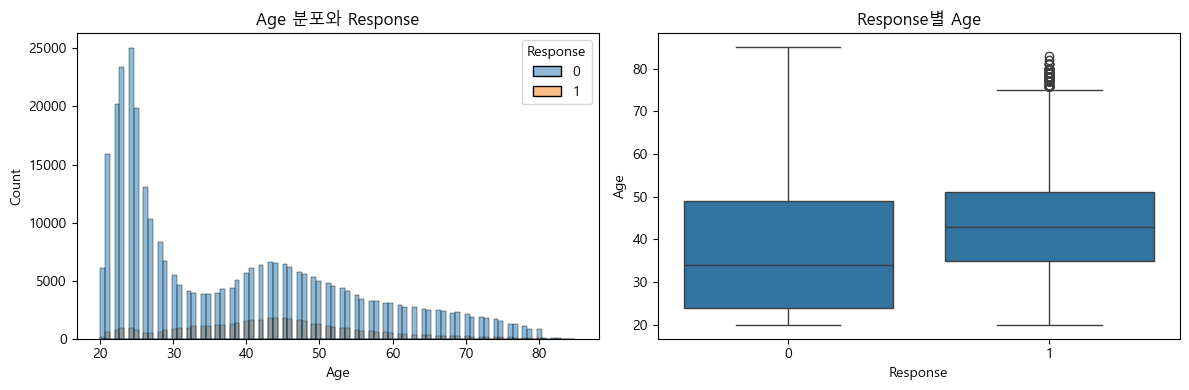

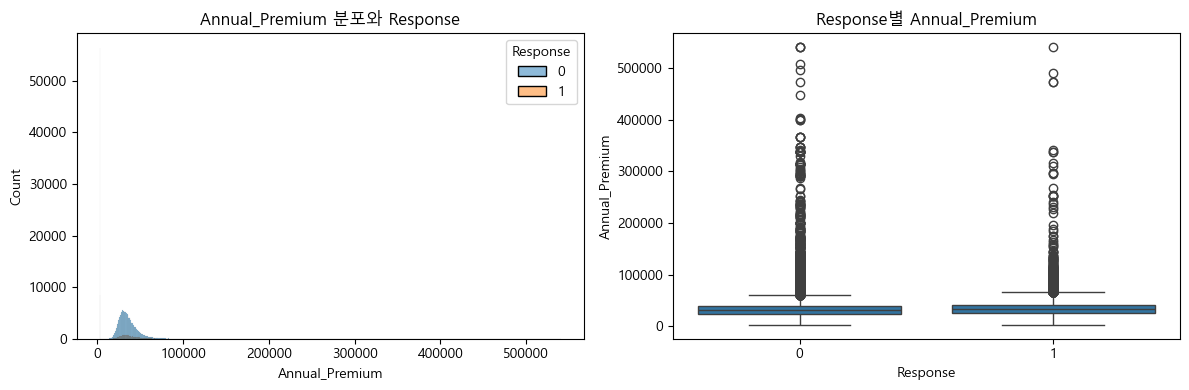

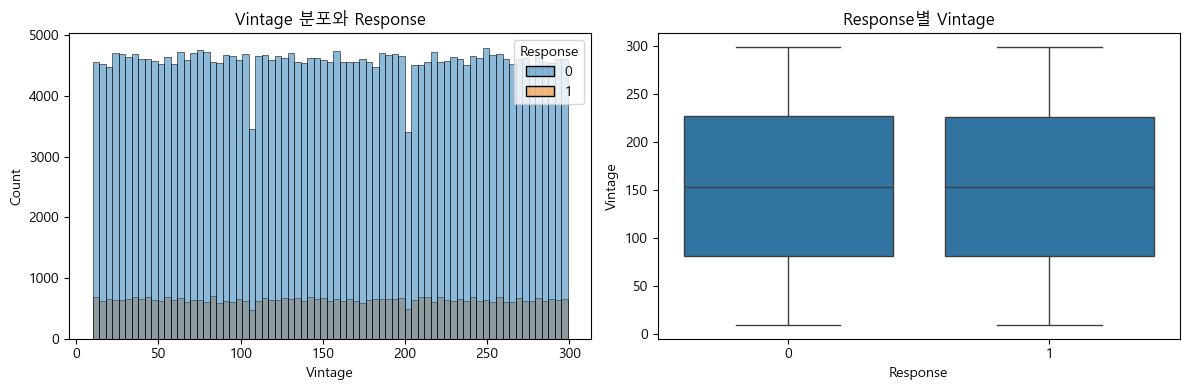

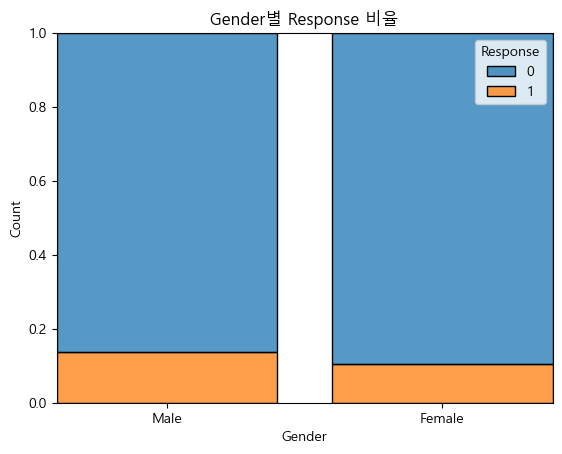

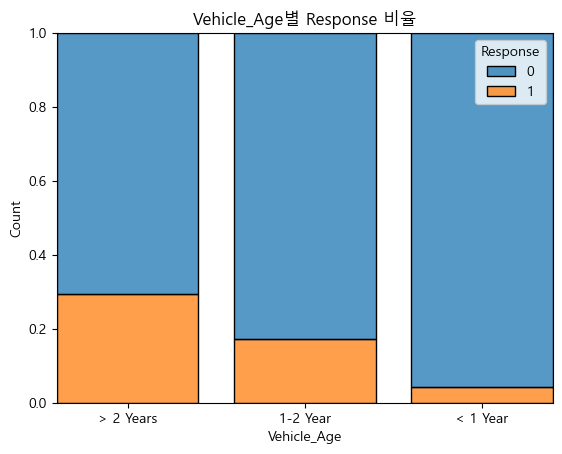

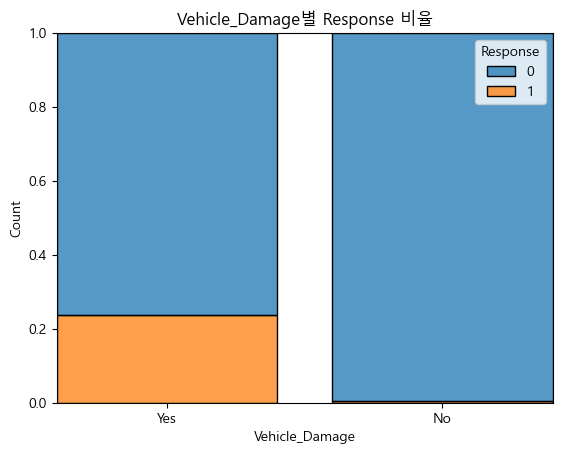

In [10]:
# column 과 타겟 변수(Response)의 상관 관계
numeric_columns = ["Age", "Annual_Premium", "Vintage"]
for column in numeric_columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 
    sns.histplot(data=train, x=column, hue="Response", ax=axes[0])
    axes[0].set_title(f"{column} 분포와 Response")
    sns.boxplot(data=train, x="Response", y=column, ax=axes[1])
    axes[1].set_title(f"Response별 {column}")
    plt.tight_layout()
    plt.show()

for column in categorical_columns:
    sns.histplot(data=train, x=column, hue="Response", multiple="fill", shrink=0.8)
    plt.title(f"{column}별 Response 비율")
    plt.show()

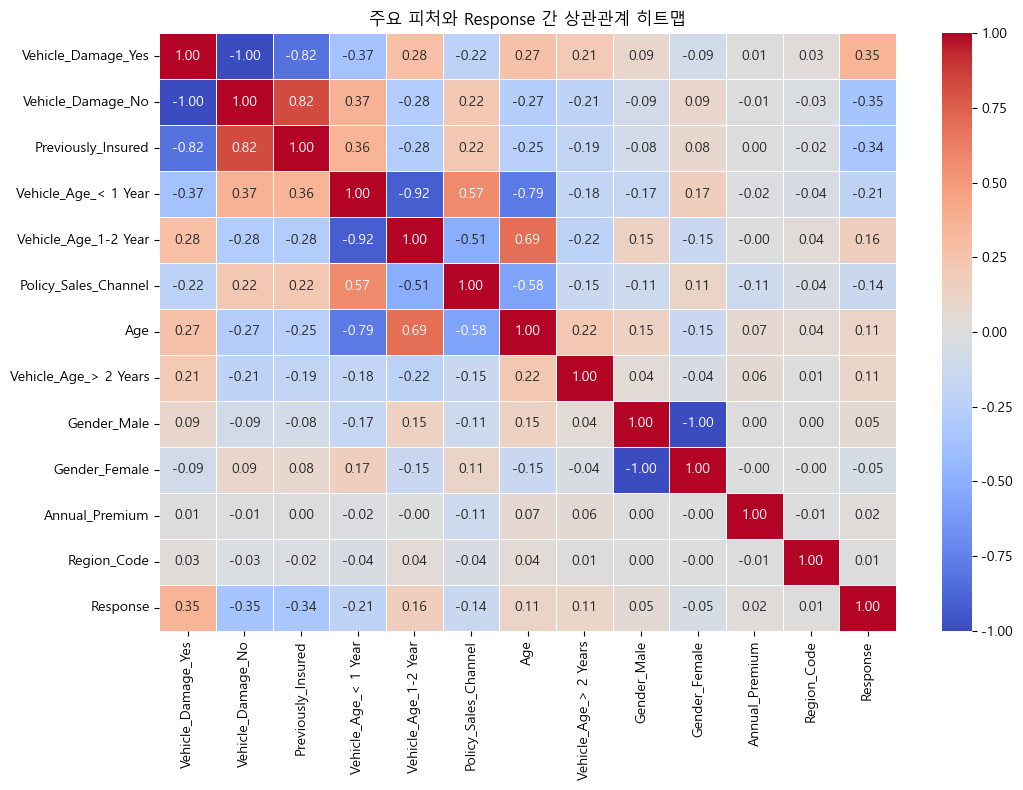

In [11]:
# 주요 피처와 타겟(Response) 간 상관관계 히트맵
# 범주형 변수는 원-핫 인코딩해 각 범주와 Response의 관계도 확인합니다.
heatmap_data = train.drop(columns=["id"], errors="ignore").copy()
heatmap_data["Response"] = pd.to_numeric(heatmap_data["Response"], errors="coerce")
heatmap_encoded = pd.get_dummies(heatmap_data, drop_first=False, dtype=int)

# 타겟과 상관관계가 큰 피처를 골라 히트맵으로 표시
target_corr = heatmap_encoded.corr(numeric_only=True)["Response"].drop("Response").dropna()
top_features = target_corr.abs().sort_values(ascending=False).head(12).index
heatmap_corr = heatmap_encoded[list(top_features) + ["Response"]].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(heatmap_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("주요 피처와 Response 간 상관관계 히트맵")
plt.tight_layout()
plt.show()


In [ ]:
# 범주형 변수의 카디널리티(고유값 개수) 확인
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder  

X = train.drop(columns=["Response", "id"]).copy()
y = train["Response"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

categorical_columns = [
    "Region_Code", "Vehicle_Age", "Policy_Sales_Channel"
]

label_encoders = {}

for column in categorical_columns:
    encoder = LabelEncoder()

    # 학습 데이터의 고유값을 기준으로 변환
    X_train[column] = encoder.fit_transform(
        X_train[column].astype(str)
    )

    # 학습 데이터의 값과 검증 데이터의 값을 연결
    value_map = {
        value: index
        for index, value in enumerate(encoder.classes_)
    }

    # 학습 데이터에 없는 값은 -1로 처리
    X_valid[column] = (
        X_valid[column].astype(str)
        .map(value_map)
        .fillna(-1)
        .astype(int)
    )

    label_encoders[column] = encoder

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_valid.shape)
print("변환 후 고유값 개수:")
print(X_train[categorical_columns].nunique())


학습 데이터: (304887, 10)
검증 데이터: (76222, 10)
변환 후 고유값 개수:
Region_Code              53
Vehicle_Age               3
Policy_Sales_Channel    154
dtype: int64
